# Vector Space Basis and Dimension Analyzer

| | |
|---|---|
| **University** | Presidency University |
| **Course Code** | MAT2303 |
| **Course Name** | Linear Algebra & Vector Calculus |
| **Mini-Project Number** | 20 |
| **Project Title** | Vector Space Basis and Dimension Analyzer |
| **Modules Covered** | 1, 2 |
| **Student Name / Reg. No.** | *Praneethaa S K* |
| **Faculty / Section** | AyEesha Banu
3CSE04|

---

## 1. Introduction and Project Aim

Given a collection of vectors, three natural questions arise:

1. Is any vector *redundant* (can it be built from the others)?
2. What is the smallest set of the original vectors that generates the same space?
3. How "big" is the space they generate?

**Aim.** To analyse several sets of vectors and determine, for each set, its **span, basis and dimension**, using exact (symbolic) linear algebra.

**Input.** Multiple sets of vectors (and, optionally, a target vector to test for membership in a span).

**Output.** Reduced Row Echelon Form (RREF), pivot positions, rank, independent/dependent classification, a basis chosen from the *original* vectors, and the dimension of the span.

## 2. Objectives

1. Convert a set of vectors into a matrix whose **columns** are the vectors.
2. Compute the **RREF**, **pivot columns** and **rank** using exact arithmetic (SymPy).
3. Decide whether the set is **linearly independent or dependent**, and express every dependent vector as a **linear combination** of the independent ones.
4. Extract a **basis** of the span from the *original* vectors.
5. Report the **dimension** of the span and describe the span in set notation.
6. Test whether a **target vector** lies in the span.
7. **Verify** every result by independent mathematical checks.

## 3. Mathematical Concepts Used

| # | Concept | Where it is used in the program |
|---|---------|---------------------------------|
| 1 | **Matrix** | `build_matrix()` places the vectors as columns of $A$ |
| 2 | **Linear combination** | `classify_independence()` writes each dependent vector as $c_1v_{i_1}+\dots+c_kv_{i_k}$ using the RREF entries |
| 3 | **Span** | `describe_span()` and `test_membership()` |
| 4 | **Linear independence / dependence** | Decided by comparing rank with the number of vectors |
| 5 | **Rank** | Number of pivots of the RREF |
| 6 | **RREF** | `compute_rref_and_rank()` row-reduces $A$ exactly |
| 7 | **Basis** | `extract_basis()` selects the original vectors at the pivot columns |
| 8 | **Dimension** | `compute_dimension()`: $\dim(\text{span}) = \text{rank}$ |

## 4. Mathematical Formulation and Formulas

Let $v_1, v_2, \dots, v_n \in \mathbb{R}^m$ be the given vectors.

**Matrix.** $A = [\,v_1 \;\; v_2 \;\; \cdots \;\; v_n\,]$ is an $m \times n$ matrix (vectors as **columns**).

**Span.**
$$\operatorname{span}\{v_1,\dots,v_n\}=\{\,c_1v_1+c_2v_2+\cdots+c_nv_n \;:\; c_1,\dots,c_n\in\mathbb{R}\,\}$$
This is exactly the **column space** of $A$.

**Linear independence.** The set is independent if $c_1v_1+\cdots+c_nv_n=\mathbf{0}$ forces $c_1=\cdots=c_n=0$, i.e. $A\mathbf{c}=\mathbf{0}$ has only the trivial solution.

**Rank.** $\operatorname{rank}(A)$ = number of pivots in $\operatorname{RREF}(A)$.

**Independence test.**
$$\operatorname{rank}(A)=n \;\Longleftrightarrow\; \text{independent};\qquad \operatorname{rank}(A)<n \;\Longleftrightarrow\; \text{dependent}.$$

**Basis theorem used.** Row operations preserve the *dependency relations among columns*. Hence the columns of $A$ in the **pivot positions** of $\operatorname{RREF}(A)$ form a basis of the column space.

> ⚠️ The basis consists of the **original columns of $A$** at the pivot positions, **not** the non-zero rows of the RREF (row operations change the column space).

**Dependent columns.** If column $j$ is a non-pivot column, then
$$v_j=\sum_{i=1}^{r} R_{i,j}\; v_{p_i}$$
where $R=\operatorname{RREF}(A)$, $r=\operatorname{rank}(A)$ and $p_1,\dots,p_r$ are the pivot columns.

**Dimension.** $\dim\operatorname{span}\{v_1,\dots,v_n\}=\operatorname{rank}(A)=$ number of basis vectors.

**Membership test.** A target vector $t\in\operatorname{span}\{v_1,\dots,v_n\}\iff\operatorname{rank}([A\,|\,t])=\operatorname{rank}(A)$.

**Rank–Nullity (used for verification).** $\operatorname{rank}(A)+\dim\operatorname{Null}(A)=n$.

## 5. Sequential Computational Workflow

The output of each stage is the input of the next:

```
Stage 0: Raw vectors ──► validated exact vectors
Stage 1: vectors      ──► Matrix A (vectors as columns)
Stage 2: A            ──► RREF(A), pivot columns, rank
Stage 3: pivots, rank ──► Independent / Dependent + dependency relations
Stage 4: pivots       ──► Basis (original vectors at pivot columns)
Stage 5: basis size   ──► Dimension of the span
Stage 6: basis        ──► Span description + target-vector membership test
```

Mathematically: **Vectors → Matrix → Row Reduction → Rank → Linear Independence → Basis Extraction → Dimension**

## 6. Required Library Imports

Only **SymPy** is needed (exact rational arithmetic, no floating-point error). **Matplotlib** is used once, for a small summary chart.

In [20]:
import sympy as sp
from sympy import Matrix, Rational

# In Jupyter / Colab, `display` shows matrices in nice mathematical form.
# If it is not available (e.g. plain Python), we fall back to printing.
try:
    from IPython.display import display
    IN_NOTEBOOK = True
except ImportError:
    IN_NOTEBOOK = False


def show_matrix(label, M):
    """Print a label and display a SymPy matrix."""
    print(label)
    if IN_NOTEBOOK:
        display(M)
    else:
        sp.pprint(M)


def fmt_vector(v):
    """Format a vector (list or column matrix) as (a, b, c)."""
    return "(" + ", ".join(str(e) for e in list(v)) + ")"


def fmt_combination(coeffs, labels):
    """Format  c1*v1 + c2*v2 ...  skipping zero coefficients."""
    parts = []
    for c, lab in zip(coeffs, labels):
        if c == 0:
            continue
        parts.append(lab if c == 1 else f"{c}·{lab}")
    if not parts:
        return "0 (zero vector)"
    return " + ".join(parts).replace("+ -", "- ")

print("SymPy version:", sp.__version__)

SymPy version: 1.14.0


## 7. Input Validation Function

Before any mathematics is done, the input is checked. The function rejects:

* anything that is not a list/tuple of vectors,
* an **empty** vector set,
* **empty** vectors,
* vectors with **different numbers of components**,
* entries that are not valid numbers.

All numbers are converted to exact `Rational` values (so `0.5` becomes `1/2`).

In [21]:
def to_exact_number(x):
    """Convert an input entry (int, float, or text like '1/2') to an exact Rational."""
    if isinstance(x, bool):
        raise ValueError(f"'{x}' is not a valid number")
    try:
        value = Rational(str(x).strip())
    except Exception:
        raise ValueError(f"'{x}' is not a valid number")
    if value.is_finite is not True:
        raise ValueError(f"'{x}' is not a valid finite number")
    return value


def validate_vector_set(vectors, set_name="vector set"):
    """Validate one vector set and return it as a list of lists of exact Rationals.
    Raises ValueError with an understandable message if the input is invalid."""
    if not isinstance(vectors, (list, tuple)):
        raise ValueError(f"{set_name}: input must be a list of vectors, e.g. [(1,0),(0,1)].")
    if len(vectors) == 0:
        raise ValueError(f"{set_name}: the vector set is EMPTY. Provide at least one vector.")

    for i, v in enumerate(vectors, start=1):
        if not isinstance(v, (list, tuple)):
            raise ValueError(f"{set_name}: vector v{i} must be a list/tuple of numbers.")
        if len(v) == 0:
            raise ValueError(f"{set_name}: vector v{i} has no components.")

    lengths = [len(v) for v in vectors]
    if len(set(lengths)) != 1:
        detail = ", ".join(f"v{i+1} has {n}" for i, n in enumerate(lengths))
        raise ValueError(f"{set_name}: all vectors must have the same number of "
                         f"components, but {detail}.")

    clean = []
    for i, v in enumerate(vectors, start=1):
        try:
            clean.append([to_exact_number(x) for x in v])
        except ValueError as err:
            raise ValueError(f"{set_name}: in vector v{i}: {err}.")
    return clean


def validate_target(target, ambient_dim, set_name="vector set"):
    """Validate a target vector against the dimension of the ambient space R^m."""
    if not isinstance(target, (list, tuple)) or len(target) == 0:
        raise ValueError(f"{set_name}: the target vector must be a non-empty list/tuple.")
    if len(target) != ambient_dim:
        raise ValueError(f"{set_name}: target has {len(target)} components but the "
                         f"vectors live in R^{ambient_dim}.")
    return [to_exact_number(x) for x in target]

print("Validation functions defined.")

Validation functions defined.


## 8. Matrix Construction Function

**Stage 1.** The validated vectors become the **columns** of the matrix $A$:
$A=[\,v_1\;v_2\;\cdots\;v_n\,]$.

In [22]:
def build_matrix(vectors):
    """Stage 1: place the vectors as COLUMNS of a SymPy matrix."""
    columns = [Matrix(v) for v in vectors]      # each vector -> m x 1 column
    return Matrix.hstack(*columns)              # join columns side by side -> m x n

# quick demonstration (not one of the test cases)
demo = build_matrix(validate_vector_set([(1, 2), (3, 4)]))
show_matrix("Demo matrix with v1=(1,2), v2=(3,4) as columns:", demo)

Demo matrix with v1=(1,2), v2=(3,4) as columns:


Matrix([
[1, 3],
[2, 4]])

## 9. RREF and Rank Calculation Function

**Stage 2.** SymPy's `rref()` performs exact Gauss–Jordan elimination and returns the RREF together with the **pivot column indices** (0-based). The **rank** is the number of pivots.

In [23]:
def compute_rref_and_rank(A):
    """Stage 2: return (RREF matrix, tuple of pivot column indices, rank)."""
    R, pivots = A.rref()            # exact arithmetic: no rounding errors
    rank = len(pivots)              # rank = number of pivot columns
    return R, pivots, rank

print("RREF / rank function defined.")

RREF / rank function defined.


## 10. Linear Independence / Dependence Function

**Stage 3.** Input: `A`, its RREF `R`, `pivots` and `rank` from Stage 2.

* If $\operatorname{rank}=n$ (number of vectors) → **linearly independent**.
* Otherwise → **linearly dependent**. Pivot columns identify the independent subset; every non-pivot column $v_j$ is a **linear combination** of the pivot vectors with coefficients read from column $j$ of the RREF.

In [24]:
def classify_independence(A, R, pivots, rank):
    """Stage 3: decide independence and find dependency relations.
    Returns a dictionary with the classification and the relations."""
    n = A.cols                                   # number of vectors
    independent = (rank == n)                    # rank = n  <=>  independent

    pivot_list = list(pivots)
    dependent_idx = [j for j in range(n) if j not in pivot_list]

    # For each non-pivot column j:  v_j = sum_i R[i, j] * v_(pivot i)
    relations = {}
    for j in dependent_idx:
        relations[j] = [R[i, j] for i in range(rank)]

    return {
        "independent": independent,
        "independent_idx": pivot_list,
        "dependent_idx": dependent_idx,
        "relations": relations,
    }

print("Independence function defined.")

Independence function defined.


## 11. Basis Extraction Function

**Stage 4.** Input: the **pivot column indices** from Stage 2.

The basis is the set of **original vectors** at those positions. (We deliberately do *not* use the non-zero rows of the RREF, since those span the *row space*, not the column space.)

In [25]:
def extract_basis(vectors, pivots):
    """Stage 4: select the ORIGINAL vectors at the pivot columns.
    Returns (list of basis vectors as column matrices, list of their 1-based labels)."""
    basis = [Matrix(vectors[j]) for j in pivots]
    labels = [f"v{j + 1}" for j in pivots]
    return basis, labels

print("Basis extraction function defined.")

Basis extraction function defined.


## 12. Dimension Calculation Function

**Stage 5.** Input: the basis from Stage 4. The **dimension** of a space is the number of vectors in any basis, and it equals the rank of $A$. The function computes it from the basis size and cross-checks it against the rank.

In [26]:
def compute_dimension(basis, rank):
    """Stage 5: dimension of the span = number of basis vectors (= rank)."""
    dimension = len(basis)
    if dimension != rank:
        raise RuntimeError("Internal error: basis size and rank disagree.")
    return dimension

print("Dimension function defined.")

Dimension function defined.


## 13. Span Description and Target-Vector Membership Function

**Stage 6.**

* `describe_span()` writes the span in set notation and describes its geometric shape.
* `test_membership()` checks whether a target $t$ lies in the span by comparing $\operatorname{rank}(A)$ with $\operatorname{rank}([A\,|\,t])$. If $t$ is in the span, it also finds the coefficients of $t$ in terms of the basis (they are unique because the basis is independent).

In [27]:
def describe_span(basis_labels, dimension, ambient_dim):
    """Stage 6a: describe span in set notation + geometric meaning."""
    if dimension == 0:
        return "span{v1, ..., vn} = {0}  (only the zero vector)", "the zero subspace {0}"

    names = ", ".join(basis_labels)
    combo = " + ".join(f"c{l[1:]}·{l}" for l in basis_labels)
    consts = ", ".join(f"c{l[1:]}" for l in basis_labels)
    notation = f"span{{{names}}} = {{ {combo} : {consts} ∈ ℝ }}"

    if dimension == ambient_dim:
        shape = f"the whole space R^{ambient_dim}"
    elif dimension == 1:
        shape = f"a line through the origin in R^{ambient_dim}"
    elif dimension == 2:
        shape = f"a plane through the origin in R^{ambient_dim}"
    else:
        shape = f"a {dimension}-dimensional subspace of R^{ambient_dim}"
    return notation, shape


def vector_in_span(basis, t):
    """True if column vector t lies in the span of the list of column vectors `basis`."""
    if len(basis) == 0:
        return all(x == 0 for x in list(t))          # span of nothing = {0}
    B = Matrix.hstack(*basis)
    return B.rank() == Matrix.hstack(B, t).rank()


def test_membership(A, basis, basis_labels, target):
    """Stage 6b: is `target` in the span?  Compare rank(A) with rank([A | t])."""
    t = Matrix(target)
    A_aug = Matrix.hstack(A, t)                      # add target as an extra column
    rank_A, rank_aug = A.rank(), A_aug.rank()
    in_span = (rank_A == rank_aug)

    result = {"target": target, "rank_A": rank_A, "rank_aug": rank_aug,
              "in_span": in_span, "expression": None}

    if in_span:
        if len(basis) == 0:
            result["expression"] = "0 (zero vector)"
        else:
            B = Matrix.hstack(*basis)
            coeffs, _ = B.gauss_jordan_solve(t)      # unique, since basis is independent
            expr = fmt_combination(list(coeffs), basis_labels)
            result["expression"] = expr
    return result

print("Span and membership functions defined.")

Span and membership functions defined.


## 14. Main Analysis Function Combining All Stages

`analyze_vector_set()` runs **Stage 0 → Stage 6** in order. Each stage uses the output of the previous one. It returns a results dictionary (used later for verification) and prints a structured report.

In [28]:
def print_report(res):
    """Print a structured, labelled report for one analysed vector set."""
    line = "=" * 70
    print(line)
    print(f"  ANALYSIS OF: {res['name']}")
    print(line)

    print("\n[Input]  Vectors in R^%d" % res["ambient_dim"])
    for i, v in enumerate(res["vectors"], start=1):
        print(f"   v{i} = {fmt_vector(v)}")

    print("\n[Stage 1]  Matrix A (vectors as columns)")
    show_matrix("   A =", res["matrix"])

    print("\n[Stage 2]  Row reduction")
    show_matrix("   RREF(A) =", res["rref"])
    print("   Pivot columns (1-based):", [j + 1 for j in res["pivots"]] or "none")
    print("   Rank(A) =", res["rank"])

    print("\n[Stage 3]  Linear independence")
    n, r = res["n_vectors"], res["rank"]
    if res["independent"]:
        print(f"   rank = {r} = number of vectors = {n}  →  LINEARLY INDEPENDENT")
    else:
        print(f"   rank = {r} < number of vectors = {n}  →  LINEARLY DEPENDENT")
        indep = ", ".join(f"v{j+1}" for j in res["independent_idx"]) or "none"
        print(f"   Independent subset (pivot vectors): {{{indep}}}")
        for j, coeffs in res["relations"].items():
            labels = [f"v{p+1}" for p in res["pivots"]]
            print(f"   v{j+1} = {fmt_combination(coeffs, labels)}")

    print("\n[Stage 4]  Basis (original vectors at pivot columns)")
    if res["basis"]:
        for lab, b in zip(res["basis_labels"], res["basis"]):
            print(f"   {lab} = {fmt_vector(b)}")
        print("   Basis = {" + ", ".join(res["basis_labels"]) + "}")
    else:
        print("   Empty basis (all vectors are zero).")

    print("\n[Stage 5]  Dimension")
    print(f"   dim(span) = rank = {res['dimension']}")

    print("\n[Stage 6]  Span")
    print("   " + res["span_notation"])
    print("   Geometrically, the span is " + res["span_shape"] + ".")

    mem = res["membership"]
    if mem is not None:
        print("\n[Target test]  Is t = %s in the span?" % fmt_vector(mem["target"]))
        print(f"   rank(A) = {mem['rank_A']},  rank([A | t]) = {mem['rank_aug']}")
        if mem["in_span"]:
            print(f"   Ranks equal  →  YES, t is in the span:  t = {mem['expression']}")
        else:
            print("   Rank increased  →  NO, t is NOT in the span.")
    print()


def analyze_vector_set(name, vectors, target=None, verbose=True):
    """Run the full pipeline: Vectors → Matrix → RREF → Rank → Independence → Basis → Dimension."""
    # Stage 0: validation
    vecs = validate_vector_set(vectors, name)
    # Stage 1: matrix
    A = build_matrix(vecs)
    # Stage 2: RREF, pivots, rank   (uses A)
    R, pivots, rank = compute_rref_and_rank(A)
    # Stage 3: independence         (uses A, R, pivots, rank)
    ind = classify_independence(A, R, pivots, rank)
    # Stage 4: basis                (uses pivots)
    basis, basis_labels = extract_basis(vecs, pivots)
    # Stage 5: dimension            (uses basis, rank)
    dimension = compute_dimension(basis, rank)
    # Stage 6: span + optional membership test (uses basis)
    notation, shape = describe_span(basis_labels, dimension, A.rows)
    membership = None
    if target is not None:
        t = validate_target(target, A.rows, name)
        membership = test_membership(A, basis, basis_labels, t)

    res = {
        "name": name, "vectors": vecs, "ambient_dim": A.rows, "n_vectors": A.cols,
        "matrix": A, "rref": R, "pivots": tuple(pivots), "rank": rank,
        "independent": ind["independent"], "independent_idx": ind["independent_idx"],
        "dependent_idx": ind["dependent_idx"], "relations": ind["relations"],
        "basis": basis, "basis_labels": basis_labels, "dimension": dimension,
        "span_notation": notation, "span_shape": shape, "membership": membership,
    }
    if verbose:
        print_report(res)
    return res


def analyze_many(vector_sets, targets=None):
    """Analyse several named vector sets. Invalid sets give a clear message instead of crashing."""
    targets = targets or {}
    out = {}
    for name, vecs in vector_sets.items():
        try:
            out[name] = analyze_vector_set(name, vecs, targets.get(name))
        except ValueError as err:
            print("=" * 70)
            print(f"  ❌ INVALID INPUT — {err}")
            print("=" * 70, "\n")
    return out

print("Main analysis function defined. Ready to run the test cases.")

Main analysis function defined. Ready to run the test cases.


## 15. Test Case 1 — Linearly Independent Vectors (standard basis of $\mathbb{R}^3$)

$v_1=(1,0,0),\; v_2=(0,1,0),\; v_3=(0,0,1)$.  
Target for the membership test: $t=(3,-2,5)$.

*Expected (checked by hand):* $A=I_3$, rank 3, independent, basis = all three vectors, dimension 3.  
The program must **compute** these — they are not typed into the code.

In [29]:
results = {}    # stores the result of every test case for later verification

results["Test 1"] = analyze_vector_set(
    "Test Case 1: Linearly independent vectors in R^3",
    [(1, 0, 0), (0, 1, 0), (0, 0, 1)],
    target=(3, -2, 5))

  ANALYSIS OF: Test Case 1: Linearly independent vectors in R^3

[Input]  Vectors in R^3
   v1 = (1, 0, 0)
   v2 = (0, 1, 0)
   v3 = (0, 0, 1)

[Stage 1]  Matrix A (vectors as columns)
   A =


Matrix([
[1, 0, 0],
[0, 1, 0],
[0, 0, 1]])


[Stage 2]  Row reduction
   RREF(A) =


Matrix([
[1, 0, 0],
[0, 1, 0],
[0, 0, 1]])

   Pivot columns (1-based): [1, 2, 3]
   Rank(A) = 3

[Stage 3]  Linear independence
   rank = 3 = number of vectors = 3  →  LINEARLY INDEPENDENT

[Stage 4]  Basis (original vectors at pivot columns)
   v1 = (1, 0, 0)
   v2 = (0, 1, 0)
   v3 = (0, 0, 1)
   Basis = {v1, v2, v3}

[Stage 5]  Dimension
   dim(span) = rank = 3

[Stage 6]  Span
   span{v1, v2, v3} = { c1·v1 + c2·v2 + c3·v3 : c1, c2, c3 ∈ ℝ }
   Geometrically, the span is the whole space R^3.

[Target test]  Is t = (3, -2, 5) in the span?
   rank(A) = 3,  rank([A | t]) = 3
   Ranks equal  →  YES, t is in the span:  t = 3·v1 - 2·v2 + 5·v3



## 16. Test Case 2 — Linearly Dependent Vectors

$v_1=(1,2,3),\; v_2=(2,4,6),\; v_3=(1,0,1)$.  
Targets: $t=(3,6,9)$ (a multiple of $v_1$, so expected inside the span) — and later $(0,0,1)$ (expected outside).

*Hand check:* $v_2=2v_1$, so the set is dependent. $v_3$ is not a multiple of $v_1$, so $\{v_1,v_3\}$ is independent → rank 2, dimension 2.

In [30]:
results["Test 2"] = analyze_vector_set(
    "Test Case 2: Linearly dependent vectors in R^3",
    [(1, 2, 3), (2, 4, 6), (1, 0, 1)],
    target=(3, 6, 9))

# Second membership test with a vector that should NOT be in the span:
print("---- Same vectors, different target ----")
res_b = analyze_vector_set(
    "Test Case 2 (target outside span)",
    [(1, 2, 3), (2, 4, 6), (1, 0, 1)],
    target=(0, 0, 1))

  ANALYSIS OF: Test Case 2: Linearly dependent vectors in R^3

[Input]  Vectors in R^3
   v1 = (1, 2, 3)
   v2 = (2, 4, 6)
   v3 = (1, 0, 1)

[Stage 1]  Matrix A (vectors as columns)
   A =


Matrix([
[1, 2, 1],
[2, 4, 0],
[3, 6, 1]])


[Stage 2]  Row reduction
   RREF(A) =


Matrix([
[1, 2, 0],
[0, 0, 1],
[0, 0, 0]])

   Pivot columns (1-based): [1, 3]
   Rank(A) = 2

[Stage 3]  Linear independence
   rank = 2 < number of vectors = 3  →  LINEARLY DEPENDENT
   Independent subset (pivot vectors): {v1, v3}
   v2 = 2·v1

[Stage 4]  Basis (original vectors at pivot columns)
   v1 = (1, 2, 3)
   v3 = (1, 0, 1)
   Basis = {v1, v3}

[Stage 5]  Dimension
   dim(span) = rank = 2

[Stage 6]  Span
   span{v1, v3} = { c1·v1 + c3·v3 : c1, c3 ∈ ℝ }
   Geometrically, the span is a plane through the origin in R^3.

[Target test]  Is t = (3, 6, 9) in the span?
   rank(A) = 2,  rank([A | t]) = 2
   Ranks equal  →  YES, t is in the span:  t = 3·v1

---- Same vectors, different target ----
  ANALYSIS OF: Test Case 2 (target outside span)

[Input]  Vectors in R^3
   v1 = (1, 2, 3)
   v2 = (2, 4, 6)
   v3 = (1, 0, 1)

[Stage 1]  Matrix A (vectors as columns)
   A =


Matrix([
[1, 2, 1],
[2, 4, 0],
[3, 6, 1]])


[Stage 2]  Row reduction
   RREF(A) =


Matrix([
[1, 2, 0],
[0, 0, 1],
[0, 0, 0]])

   Pivot columns (1-based): [1, 3]
   Rank(A) = 2

[Stage 3]  Linear independence
   rank = 2 < number of vectors = 3  →  LINEARLY DEPENDENT
   Independent subset (pivot vectors): {v1, v3}
   v2 = 2·v1

[Stage 4]  Basis (original vectors at pivot columns)
   v1 = (1, 2, 3)
   v3 = (1, 0, 1)
   Basis = {v1, v3}

[Stage 5]  Dimension
   dim(span) = rank = 2

[Stage 6]  Span
   span{v1, v3} = { c1·v1 + c3·v3 : c1, c3 ∈ ℝ }
   Geometrically, the span is a plane through the origin in R^3.

[Target test]  Is t = (0, 0, 1) in the span?
   rank(A) = 2,  rank([A | t]) = 3
   Rank increased  →  NO, t is NOT in the span.



## 17. Test Case 3 — Two Independent Vectors in $\mathbb{R}^3$

$v_1=(1,2,0),\; v_2=(0,1,1)$.  Target: $t=(1,3,1)$.

*Hand check:* neither vector is a multiple of the other → independent, rank 2, dimension 2. Since $v_1+v_2=(1,3,1)$, the target should be in the span. Note that only 2 vectors cannot span all of $\mathbb{R}^3$ — the span is a **plane**.

In [31]:
results["Test 3"] = analyze_vector_set(
    "Test Case 3: Two independent vectors in R^3",
    [(1, 2, 0), (0, 1, 1)],
    target=(1, 3, 1))

  ANALYSIS OF: Test Case 3: Two independent vectors in R^3

[Input]  Vectors in R^3
   v1 = (1, 2, 0)
   v2 = (0, 1, 1)

[Stage 1]  Matrix A (vectors as columns)
   A =


Matrix([
[1, 0],
[2, 1],
[0, 1]])


[Stage 2]  Row reduction
   RREF(A) =


Matrix([
[1, 0],
[0, 1],
[0, 0]])

   Pivot columns (1-based): [1, 2]
   Rank(A) = 2

[Stage 3]  Linear independence
   rank = 2 = number of vectors = 2  →  LINEARLY INDEPENDENT

[Stage 4]  Basis (original vectors at pivot columns)
   v1 = (1, 2, 0)
   v2 = (0, 1, 1)
   Basis = {v1, v2}

[Stage 5]  Dimension
   dim(span) = rank = 2

[Stage 6]  Span
   span{v1, v2} = { c1·v1 + c2·v2 : c1, c2 ∈ ℝ }
   Geometrically, the span is a plane through the origin in R^3.

[Target test]  Is t = (1, 3, 1) in the span?
   rank(A) = 2,  rank([A | t]) = 2
   Ranks equal  →  YES, t is in the span:  t = v1 + v2



## 18. Test Case 4 — Zero Vector and Dependence in $\mathbb{R}^2$

$v_1=(1,2),\; v_2=(0,0),\; v_3=(2,4)$.  Target: $t=(3,6)$.

*Hand check:* $v_2=\mathbf{0}=0\cdot v_1$ and $v_3=2v_1$. Any set containing the zero vector is dependent. Only $v_1$ is needed → rank 1, basis $\{v_1\}$, dimension 1 (a line in $\mathbb{R}^2$).

In [32]:
results["Test 4"] = analyze_vector_set(
    "Test Case 4: Zero vector and dependence in R^2",
    [(1, 2), (0, 0), (2, 4)],
    target=(3, 6))

  ANALYSIS OF: Test Case 4: Zero vector and dependence in R^2

[Input]  Vectors in R^2
   v1 = (1, 2)
   v2 = (0, 0)
   v3 = (2, 4)

[Stage 1]  Matrix A (vectors as columns)
   A =


Matrix([
[1, 0, 2],
[2, 0, 4]])


[Stage 2]  Row reduction
   RREF(A) =


Matrix([
[1, 0, 2],
[0, 0, 0]])

   Pivot columns (1-based): [1]
   Rank(A) = 1

[Stage 3]  Linear independence
   rank = 1 < number of vectors = 3  →  LINEARLY DEPENDENT
   Independent subset (pivot vectors): {v1}
   v2 = 0 (zero vector)
   v3 = 2·v1

[Stage 4]  Basis (original vectors at pivot columns)
   v1 = (1, 2)
   Basis = {v1}

[Stage 5]  Dimension
   dim(span) = rank = 1

[Stage 6]  Span
   span{v1} = { c1·v1 : c1 ∈ ℝ }
   Geometrically, the span is a line through the origin in R^2.

[Target test]  Is t = (3, 6) in the span?
   rank(A) = 1,  rank([A | t]) = 1
   Ranks equal  →  YES, t is in the span:  t = 3·v1



## 19. Try Your Own Vector Sets

**How to use:** edit the dictionary `MY_VECTOR_SETS` below, then re-run the cell (Shift+Enter).

* Each key is a name; each value is a list of vectors written as tuples.
* All vectors **in one set** must have the same number of components.
* Entries may be integers, decimals (`0.5`) or fractions written as text (`"1/3"`).
* Optionally add a target vector in `MY_TARGETS` (use the same key) to test membership. Delete a line to skip the test.

The second cell deliberately contains **invalid** sets to show the error messages.

In [33]:
# ======================  EDIT HERE  ======================
MY_VECTOR_SETS = {
    "My Set A (R^4)":  [(1, 0, 2, 1), (0, 1, 1, 0), (1, 1, 3, 1), (2, 1, 5, 2)],
    "My Set B (R^2)":  [(1, 2), (3, 4), (5, 6)],
    "My Set C (R^3)":  [(1, 2, 3), ("1/2", 1, "3/2")],
}

MY_TARGETS = {
    "My Set A (R^4)": (3, 2, 8, 3),
    "My Set B (R^2)": (7, -1),
}
# =========================================================

my_results = analyze_many(MY_VECTOR_SETS, MY_TARGETS)

  ANALYSIS OF: My Set A (R^4)

[Input]  Vectors in R^4
   v1 = (1, 0, 2, 1)
   v2 = (0, 1, 1, 0)
   v3 = (1, 1, 3, 1)
   v4 = (2, 1, 5, 2)

[Stage 1]  Matrix A (vectors as columns)
   A =


Matrix([
[1, 0, 1, 2],
[0, 1, 1, 1],
[2, 1, 3, 5],
[1, 0, 1, 2]])


[Stage 2]  Row reduction
   RREF(A) =


Matrix([
[1, 0, 1, 2],
[0, 1, 1, 1],
[0, 0, 0, 0],
[0, 0, 0, 0]])

   Pivot columns (1-based): [1, 2]
   Rank(A) = 2

[Stage 3]  Linear independence
   rank = 2 < number of vectors = 4  →  LINEARLY DEPENDENT
   Independent subset (pivot vectors): {v1, v2}
   v3 = v1 + v2
   v4 = 2·v1 + v2

[Stage 4]  Basis (original vectors at pivot columns)
   v1 = (1, 0, 2, 1)
   v2 = (0, 1, 1, 0)
   Basis = {v1, v2}

[Stage 5]  Dimension
   dim(span) = rank = 2

[Stage 6]  Span
   span{v1, v2} = { c1·v1 + c2·v2 : c1, c2 ∈ ℝ }
   Geometrically, the span is a plane through the origin in R^4.

[Target test]  Is t = (3, 2, 8, 3) in the span?
   rank(A) = 2,  rank([A | t]) = 2
   Ranks equal  →  YES, t is in the span:  t = 3·v1 + 2·v2

  ANALYSIS OF: My Set B (R^2)

[Input]  Vectors in R^2
   v1 = (1, 2)
   v2 = (3, 4)
   v3 = (5, 6)

[Stage 1]  Matrix A (vectors as columns)
   A =


Matrix([
[1, 3, 5],
[2, 4, 6]])

... (3 outputs left out)

Matrix([
[1, 1/2],
[2,   1],
[3, 3/2]])


[Stage 2]  Row reduction
   RREF(A) =


Matrix([
[1, 1/2],
[0,   0],
[0,   0]])

   Pivot columns (1-based): [1]
   Rank(A) = 1

[Stage 3]  Linear independence
   rank = 1 < number of vectors = 2  →  LINEARLY DEPENDENT
   Independent subset (pivot vectors): {v1}
   v2 = 1/2·v1

[Stage 4]  Basis (original vectors at pivot columns)
   v1 = (1, 2, 3)
   Basis = {v1}

[Stage 5]  Dimension
   dim(span) = rank = 1

[Stage 6]  Span
   span{v1} = { c1·v1 : c1 ∈ ℝ }
   Geometrically, the span is a line through the origin in R^3.



In [34]:
# Deliberately INVALID inputs, to demonstrate the validation messages:
INVALID_SETS = {
    "Empty set":                [],
    "Unequal lengths":          [(1, 2, 3), (4, 5)],
    "Non-numeric entry":        [(1, 2), (3, "abc")],
    "Not a list of vectors":    "hello",
    "Empty vector inside set":  [(1, 2), ()],
}
_ = analyze_many(INVALID_SETS)

  ❌ INVALID INPUT — Empty set: the vector set is EMPTY. Provide at least one vector.

  ❌ INVALID INPUT — Unequal lengths: all vectors must have the same number of components, but v1 has 3, v2 has 2.

  ❌ INVALID INPUT — Non-numeric entry: in vector v2: 'abc' is not a valid number.

  ❌ INVALID INPUT — Not a list of vectors: input must be a list of vectors, e.g. [(1,0),(0,1)].

  ❌ INVALID INPUT — Empty vector inside set: vector v2 has no components.



## 20. Verification of Results

The results are verified in **three independent ways**:

**(A) Internal mathematical checks** (run on every test case, using different methods from the main pipeline):

1. The number of RREF pivots equals SymPy's own `rank()`.
2. The chosen basis vectors are linearly independent.
3. **Every** original vector lies in the span of the basis (so the basis spans the *same* space).
4. dimension = rank = number of basis vectors.
5. Rank–Nullity: $\operatorname{rank}(A)+\dim\operatorname{Null}(A)=n$.
6. Each dependency relation reproduces the dependent vector exactly.

**(B) Comparison with the hand-calculated expected answers** from the project specification (these values are used *only* for comparison, never to produce the output).

**(C) A demonstration** of why RREF rows must not be used as the basis.

In [35]:
def verify_result(res):
    """Run independent checks on one result dictionary. Returns list of (description, passed)."""
    A = res["matrix"]
    vecs = [Matrix(v) for v in res["vectors"]]
    basis = res["basis"]
    checks = []

    checks.append(("RREF pivot count equals SymPy rank(A)",
                   len(res["pivots"]) == A.rank()))

    if basis:
        basis_independent = Matrix.hstack(*basis).rank() == len(basis)
    else:
        basis_independent = True
    checks.append(("Basis vectors are linearly independent", basis_independent))

    checks.append(("Every original vector lies in span(basis)",
                   all(vector_in_span(basis, v) for v in vecs)))

    checks.append(("dimension = rank = number of basis vectors",
                   res["dimension"] == res["rank"] == len(basis)))

    checks.append(("Rank–Nullity: rank + dim Null(A) = number of vectors",
                   res["rank"] + len(A.nullspace()) == res["n_vectors"]))

    relations_ok = True
    for j, coeffs in res["relations"].items():
        rebuilt = Matrix.zeros(A.rows, 1)
        for c, b in zip(coeffs, basis):
            rebuilt += c * b
        if rebuilt != vecs[j]:
            relations_ok = False
    checks.append(("Dependency relations reproduce dependent vectors exactly", relations_ok))
    return checks


all_ok = True
for key, res in results.items():
    print(f"--- {key}: {res['name']}")
    for desc, passed in verify_result(res):
        print(f"   [{'PASS' if passed else 'FAIL'}] {desc}")
        all_ok = all_ok and passed
print("\nAll internal checks passed:", all_ok)

--- Test 1: Test Case 1: Linearly independent vectors in R^3
   [PASS] RREF pivot count equals SymPy rank(A)
   [PASS] Basis vectors are linearly independent
   [PASS] Every original vector lies in span(basis)
   [PASS] dimension = rank = number of basis vectors
   [PASS] Rank–Nullity: rank + dim Null(A) = number of vectors
   [PASS] Dependency relations reproduce dependent vectors exactly
--- Test 2: Test Case 2: Linearly dependent vectors in R^3
   [PASS] RREF pivot count equals SymPy rank(A)
   [PASS] Basis vectors are linearly independent
   [PASS] Every original vector lies in span(basis)
   [PASS] dimension = rank = number of basis vectors
   [PASS] Rank–Nullity: rank + dim Null(A) = number of vectors
   [PASS] Dependency relations reproduce dependent vectors exactly
--- Test 3: Test Case 3: Two independent vectors in R^3
   [PASS] RREF pivot count equals SymPy rank(A)
   [PASS] Basis vectors are linearly independent
   [PASS] Every original vector lies in span(basis)
   [PASS] d

In [36]:
# (B) Compare computed results with the hand-calculated expected answers.
# Expected values come from the project specification and are used ONLY for checking.
expected = {
    "Test 1": {"rank": 3, "independent": True,  "basis": ["v1", "v2", "v3"], "dim": 3},
    "Test 2": {"rank": 2, "independent": False, "basis": ["v1", "v3"],       "dim": 2},
    "Test 3": {"rank": 2, "independent": True,  "basis": ["v1", "v2"],       "dim": 2},
    "Test 4": {"rank": 1, "independent": False, "basis": ["v1"],             "dim": 1},
}

print(f"{'Test':<8}{'Rank':>10}{'Independent':>16}{'Basis':>20}{'Dim':>8}   Match?")
print("-" * 72)
for key, exp in expected.items():
    r = results[key]
    got = (r["rank"], r["independent"], r["basis_labels"], r["dimension"])
    want = (exp["rank"], exp["independent"], exp["basis"], exp["dim"])
    match = (got == want)
    all_ok = all_ok and match
    print(f"{key:<8}{str(r['rank']) + '/' + str(exp['rank']):>10}"
          f"{str(r['independent']) + '/' + str(exp['independent']):>16}"
          f"{','.join(r['basis_labels']):>20}{str(r['dimension']) + '/' + str(exp['dim']):>8}   "
          f"{'✔' if match else '✘'}")
print("(each cell shows computed/expected)")

# Extra relation checks stated in the specification:
r2 = results["Test 2"]["vectors"]
rel_ok = (r2[1] == [2 * x for x in r2[0]])
print("\nTest 2: v2 = 2·v1 ?", rel_ok)
all_ok = all_ok and rel_ok

assert all_ok, "Some verification check failed!"
print("\n✅ ALL VERIFICATION CHECKS PASSED for the four mandatory test cases.")

Test          Rank     Independent               Basis     Dim   Match?
------------------------------------------------------------------------
Test 1         3/3       True/True            v1,v2,v3     3/3   ✔
Test 2         2/2     False/False               v1,v3     2/2   ✔
Test 3         2/2       True/True               v1,v2     2/2   ✔
Test 4         1/1     False/False                  v1     1/1   ✔
(each cell shows computed/expected)

Test 2: v2 = 2·v1 ? True

✅ ALL VERIFICATION CHECKS PASSED for the four mandatory test cases.


In [37]:
# (C) Why we must NOT use RREF rows as the basis -- demonstration with Test 2.
res = results["Test 2"]
R = res["rref"]
print("RREF(A) of Test 2:")
show_matrix("", R)

print("Non-zero RREF rows tested for membership in span{v1, v3} (the true column space):")
for i in range(res["rank"]):
    row_vec = R.row(i).T                      # turn the row into a column vector
    inside = vector_in_span(res["basis"], row_vec)
    print(f"   RREF row {i+1} = {fmt_vector(row_vec)}  in the column space?  {inside}")

print("\nConclusion: row operations change the column space, so RREF rows are NOT a basis")
print("of the span of the original vectors. The ORIGINAL pivot-column vectors are.")

RREF(A) of Test 2:



Matrix([
[1, 2, 0],
[0, 0, 1],
[0, 0, 0]])

Non-zero RREF rows tested for membership in span{v1, v3} (the true column space):
   RREF row 1 = (1, 2, 0)  in the column space?  False
   RREF row 2 = (0, 0, 1)  in the column space?  False

Conclusion: row operations change the column space, so RREF rows are NOT a basis
of the span of the original vectors. The ORIGINAL pivot-column vectors are.


## 21. Interpretation of Results

The table and chart below are generated from the computed results.

Test case   #Vectors   Rank  Dim(span)  Status        Basis
----------------------------------------------------------------------
Test 1             3      3          3  Independent   {v1, v2, v3}
Test 2             3      2          2  Dependent     {v1, v3}
Test 3             2      2          2  Independent   {v1, v2}
Test 4             3      1          1  Dependent     {v1}


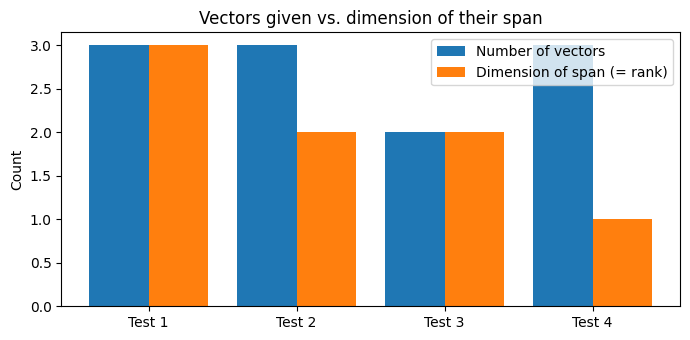

In [38]:
print(f"{'Test case':<10}{'#Vectors':>10}{'Rank':>7}{'Dim(span)':>11}  {'Status':<14}Basis")
print("-" * 70)
for key, r in results.items():
    status = "Independent" if r["independent"] else "Dependent"
    print(f"{key:<10}{r['n_vectors']:>10}{r['rank']:>7}{r['dimension']:>11}  {status:<14}"
          f"{{{', '.join(r['basis_labels'])}}}")

# Simple chart: number of vectors vs. dimension of their span
try:
    import matplotlib.pyplot as plt
    names = list(results.keys())
    counts = [results[k]["n_vectors"] for k in names]
    dims = [results[k]["dimension"] for k in names]
    x = range(len(names))
    plt.figure(figsize=(7, 3.5))
    plt.bar([i - 0.2 for i in x], counts, width=0.4, label="Number of vectors")
    plt.bar([i + 0.2 for i in x], dims, width=0.4, label="Dimension of span (= rank)")
    plt.xticks(list(x), names)
    plt.ylabel("Count")
    plt.title("Vectors given vs. dimension of their span")
    plt.legend()
    plt.tight_layout()
    plt.show()
except ImportError:
    print("(matplotlib not available - chart skipped)")

**What the results mean**

| Test | Interpretation |
|------|----------------|
| **1** | Three independent vectors in $\mathbb{R}^3$: nothing is redundant, so the span is **all of $\mathbb{R}^3$** and the three vectors form a basis (dimension 3). |
| **2** | $v_2=2v_1$ adds nothing new, so one vector is redundant. The span is a **plane** through the origin with basis $\{v_1,v_3\}$ (dimension 2). The target $(3,6,9)=3v_1$ lies in this plane, while $(0,0,1)$ does not (its rank test raises the rank to 3). |
| **3** | Two independent vectors in $\mathbb{R}^3$ span a **plane** (dimension 2). They cannot reach every vector in $\mathbb{R}^3$, because a basis of $\mathbb{R}^3$ needs 3 vectors. |
| **4** | The zero vector never contributes to a span, and $v_3=2v_1$. Only $v_1$ is needed, giving a **line** through the origin in $\mathbb{R}^2$ (dimension 1). |

**General observations**

* The number of vectors can exceed the dimension of their span; the *difference* ($n-\text{rank}$) counts the redundant vectors.
* The dimension of the span can never exceed the number of components $m$ nor the number of vectors $n$: $\;\dim\le\min(m,n)$.
* A basis is **not unique** (e.g. $\{v_2,v_3\}$ would also work in Test 2), but the **dimension is always the same**. The program returns the first independent vectors, as selected by the pivot columns.

## 22. Conclusion

This project built a complete, modular **Vector Space Basis and Dimension Analyzer** in Python using exact SymPy arithmetic. Eight linear-algebra concepts — matrix, linear combination, span, linear independence/dependence, basis, dimension, rank and RREF — were combined into one sequential pipeline:

**Vectors → Matrix → RREF → Rank → Independence → Basis → Dimension**

in which each stage's output is the next stage's input. The program validated its input, handled zero and dependent vectors correctly, extracted bases from the **original vectors** at the pivot columns, and tested target-vector membership using rank comparison.

All four mandatory test cases were computed dynamically (no answers are hard-coded) and agreed with the hand-calculated expected results. The results were further confirmed by independent checks: basis independence, span equality, rank–nullity and exact reconstruction of dependent vectors.

**Possible extensions:** finding the null space (the exact dependency relations), Gram–Schmidt orthogonalisation of the basis, and extension of a basis to a basis of the whole space $\mathbb{R}^m$.

**Limitations:** the program works over the real (rational) numbers and is intended for small, classroom-sized examples.

---
*End of notebook — Presidency University, MAT2303, Mini-Project 20.*